# Guilt by Association: Graph-Augmented ML for Healthcare Insurance Fraud Detection

MSc AI & Data Science dissertation (University of East London, 2026), Adesanmi Adetoba.

Pipeline: claims → provider features → shared-beneficiary provider graph → local / community / global graph features → five-model XGBoost ablation → bootstrap significance → SHAP → error analysis.

Outputs below are from the run reported in the repository README.

## 1. Setup
Set `DATA` to the folder holding the four Kaggle CSVs. On Kaggle, attach the *Healthcare Provider Fraud Detection Analysis* dataset and the default path works.

In [55]:
import pandas as pd
import numpy as np
import networkx as nx
from networkx.algorithms.community import louvain_communities
import xgboost as xgb
import shap
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (average_precision_score, f1_score,
                              recall_score, precision_score, roc_auc_score)
from sklearn.inspection import permutation_importance
from imblearn.over_sampling import SMOTE
from scipy import stats
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings, time, os, json
warnings.filterwarnings('ignore')
 
ON_KAGGLE = os.path.exists('/kaggle/input')
OUT = '/kaggle/working/outputs' if ON_KAGGLE else 'outputs'
os.makedirs(OUT, exist_ok=True)
 
# Dataset paths on Kaggle
DATA = ('/kaggle/input/datasets/rohitrox/healthcare-provider-fraud-detection-analysis'
        if ON_KAGGLE else 'data')
 
print("Libraries loaded.")
print("="*60)

Libraries loaded.


## 2. Load and merge claims
Inpatient and outpatient claims are unioned and joined to beneficiary data: 558,211 claims, 5,410 labelled providers.

In [56]:
print("\nSECTION 2: Loading data...")
 
train   = pd.read_csv(f'{DATA}/Train-1542865627584.csv')
bene    = pd.read_csv(f'{DATA}/Train_Beneficiarydata-1542865627584.csv')
inp     = pd.read_csv(f'{DATA}/Train_Inpatientdata-1542865627584.csv')
out_df  = pd.read_csv(f'{DATA}/Train_Outpatientdata-1542865627584.csv')
 
print(f"Providers with labels: {len(train):,}")
print(f"Beneficiaries:         {len(bene):,}")
print(f"Inpatient claims:      {len(inp):,}")
print(f"Outpatient claims:     {len(out_df):,}")
 
# Mark which claims are inpatient vs outpatient
inp['IsInpatient']    = 1
out_df['IsInpatient'] = 0
 
# Union of claims on common columns
common_cols = list(set(inp.columns) & set(out_df.columns))
claims = pd.concat([inp[common_cols], out_df[common_cols]], ignore_index=True)
print(f"\nTotal merged claims: {len(claims):,}")
 
# Join beneficiary data
claims = claims.merge(bene, on='BeneID', how='left')
 
# Compute beneficiary age at time of claim
claims['ClaimStartDt'] = pd.to_datetime(claims['ClaimStartDt'], errors='coerce')
claims['DOB']          = pd.to_datetime(claims['DOB'], errors='coerce')
diff = claims['ClaimStartDt'] - claims['DOB']
claims['Age']          = (diff.dt.days / 365.25).clip(0, 120)
claims['Age']          = claims['Age'].fillna(0)
# Count chronic conditions per beneficiary
chronic_cols = [c for c in bene.columns if c.startswith('ChronicCond_')]
for c in chronic_cols:
    claims[c] = pd.to_numeric(claims[c], errors='coerce').fillna(0)
claims['NumChronicConds'] = claims[chronic_cols].sum(axis=1)
 
# Inpatient stay length
claims['AdmissionDt']  = pd.to_datetime(claims['AdmissionDt'], errors='coerce') if 'AdmissionDt' in claims.columns else pd.NaT
claims['DischargeDt']  = pd.to_datetime(claims['DischargeDt'], errors='coerce') if 'DischargeDt' in claims.columns else pd.NaT
stay_diff = claims['DischargeDt'] - claims['AdmissionDt']
claims['StayLength']   = stay_diff.dt.days.fillna(0)
print("Data merged and enriched.")


SECTION 2: Loading data...
Providers with labels: 5,410
Beneficiaries:         138,556
Inpatient claims:      40,474
Outpatient claims:     517,737

Total merged claims: 558,211
Data merged and enriched.


## 3. Tabular baseline features (17 per provider)
Billing volume, physician diversity, beneficiary profile, clinical complexity and care-pattern features. These form model M1.

In [57]:

print("\nSECTION 3: Building tabular features per provider...")
 
def aggregate_provider(g):
    return pd.Series({
        'NumClaims':                 len(g),
        'TotalReimbursed':           g['InscClaimAmtReimbursed'].sum(),
        'MeanReimbursed':            g['InscClaimAmtReimbursed'].mean(),
        'MedianReimbursed':          g['InscClaimAmtReimbursed'].median(),
        'StdReimbursed':             g['InscClaimAmtReimbursed'].std(),
        'MaxReimbursed':             g['InscClaimAmtReimbursed'].max(),
        'MeanDeductible':            g['DeductibleAmtPaid'].mean() if 'DeductibleAmtPaid' in g else 0,
        'NumUniqueBeneficiaries':    g['BeneID'].nunique(),
        'NumUniqueAttPhys':          g['AttendingPhysician'].nunique(),
        'NumUniqueOpPhys':           g['OperatingPhysician'].nunique(),
        'NumUniqueOthPhys':          g['OtherPhysician'].nunique(),
        'MeanAge':                   g['Age'].mean(),
        'StdAge':                    g['Age'].std(),
        'MeanChronicConds':          g['NumChronicConds'].mean(),
        'InpatientRatio':            g['IsInpatient'].mean(),
        'MeanStayLength':            g['StayLength'].mean(),
        'PctDeceased':               (g['DOD'].notna()).mean() if 'DOD' in g else 0,
    })
 
providers = claims.groupby('Provider').apply(aggregate_provider).reset_index()
providers = providers.merge(train, on='Provider', how='left')
providers['Label'] = (providers['PotentialFraud'] == 'Yes').astype(int)
providers = providers.drop(columns=['PotentialFraud']).fillna(0)
 
print(f"Provider table shape: {providers.shape}")
print(f"Fraud rate: {providers['Label'].mean()*100:.2f}%")
print(f"Fraud cases: {providers['Label'].sum()} of {len(providers)}")
 


SECTION 3: Building tabular features per provider...
Provider table shape: (5410, 19)
Fraud rate: 9.35%
Fraud cases: 506 of 5410


## 4. Provider–provider graph
Two providers are linked if they treated at least one shared beneficiary; edge weight = number of shared beneficiaries.

In [58]:
print("\nSECTION 4: Building provider-provider graph...")
t0 = time.time()
 
# For each beneficiary, get the list of providers who treated them
bene_providers = (claims.groupby('BeneID')['Provider']
                  .unique().reset_index())
 
# Build edge weights: how many shared beneficiaries per provider pair?
from collections import defaultdict
edge_weights = defaultdict(int)
for _, row in bene_providers.iterrows():
    provs = sorted(row['Provider'])
    for i in range(len(provs)):
        for j in range(i+1, len(provs)):
            edge_weights[(provs[i], provs[j])] += 1
 
print(f"  Edge building done: {len(edge_weights):,} unique edges ({time.time()-t0:.0f}s)")
 
# Create the NetworkX graph
G = nx.Graph()
G.add_nodes_from(providers['Provider'].tolist())
for (u, v), w in edge_weights.items():
    G.add_edge(u, v, weight=w)
 
print(f"  Graph: {G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges")
ccs = sorted(nx.connected_components(G), key=len, reverse=True)
print(f"  Connected components: {len(ccs)}")
print(f"  Largest component: {len(ccs[0]):,} providers")
degrees = [G.degree(n) for n in G.nodes()]
print(f"  Degree: mean={np.mean(degrees):.1f}, max={max(degrees)}")


SECTION 4: Building provider-provider graph...
  Edge building done: 168,104 unique edges (10s)
  Graph: 5,410 nodes, 168,104 edges
  Connected components: 30
  Largest component: 5,381 providers
  Degree: mean=62.1, max=1347


## 5. Local features
Degree, weighted degree, clustering coefficient.

In [59]:
# ────────────────────────────────────────────────────────────────
# SECTION 5: COMPUTE LOCAL GRAPH FEATURES
# What this does: for each provider, measures their immediate
# neighbourhood. Three features:
# - degree: how many providers they are connected to
# - weighted_degree: total weight (shared patients) of connections
# - clustering: how tightly their neighbours connect to each other
# ────────────────────────────────────────────────────────────────
 
print("\nSECTION 5: Computing LOCAL features...")
t0 = time.time()
 
local_feats = pd.DataFrame({'Provider': list(G.nodes())})
local_feats['local_degree']          = local_feats['Provider'].map(dict(G.degree()))
local_feats['local_weighted_degree'] = local_feats['Provider'].map(
    dict(G.degree(weight='weight')))
clust = nx.clustering(G)
local_feats['local_clustering']      = local_feats['Provider'].map(clust)
print(f"  Local features done ({time.time()-t0:.0f}s)")


SECTION 5: Computing LOCAL features...
  Local features done (8s)


## 6. Community features + Louvain stability check
Louvain communities (seed 42), plus Adjusted Rand Index across 10 seeds to show the partition is stable.

In [60]:
# SECTION 6: COMPUTE COMMUNITY FEATURES + STABILITY CHECK
# What this does: runs the Louvain algorithm to find natural
# groupings (communities) of providers.
# Then for each provider:
# - community_size: how big their group is
# - community_fraud_rate: % of fraud in their group
#   (computed from training labels only to prevent data leakage)
#
# Stability check: runs Louvain 10 times with different seeds
# and measures how consistent the results are (ARI score).
# A score near 1.0 = very stable. Score reported in Chapter 4.
# ────────────────────────────────────────────────────────────────
 
print("\nSECTION 6: Computing COMMUNITY features...")
t0 = time.time()
 
# Run Louvain with seed=42 (our main run)
communities = louvain_communities(G, seed=42, weight='weight')
print(f"  Found {len(communities)} communities ({time.time()-t0:.0f}s)")
sizes = sorted([len(c) for c in communities], reverse=True)
print(f"  Top 5 community sizes: {sizes[:5]}")
 
# Map provider -> community label
prov2comm = {}
for i, comm in enumerate(communities):
    for p in comm:
        prov2comm[p] = i
 
comm_feats = pd.DataFrame({'Provider': list(G.nodes())})
comm_feats['community_label'] = comm_feats['Provider'].map(prov2comm)
comm_feats['community_size']  = comm_feats['community_label'].map(
    lambda c: len(communities[c]))
 
# Stability check: 10 seeds, compute Adjusted Rand Index
from sklearn.metrics import adjusted_rand_score
nodes = list(G.nodes())
partitions = []
n_comms = []
print("  Running stability check (10 seeds)...")
for seed in range(10):
    comms = louvain_communities(G, seed=seed, weight='weight')
    n_comms.append(len(comms))
    p2c = {}
    for i, c in enumerate(comms):
        for p in c:
            p2c[p] = i
    partitions.append([p2c.get(p, -1) for p in nodes])
 
ari_scores = []
for i in range(10):
    for j in range(i+1, 10):
        ari_scores.append(adjusted_rand_score(partitions[i], partitions[j]))
 
ari_mean = np.mean(ari_scores)
ari_std  = np.std(ari_scores)
ari_min  = np.min(ari_scores)
ari_max  = np.max(ari_scores)
 
print(f"  Louvain stability ARI: mean={ari_mean:.3f} std={ari_std:.3f} "
      f"min={ari_min:.3f} max={ari_max:.3f}")
print(f"  Communities per seed: {n_comms}")
 
# Save stability results
with open(f'{OUT}/louvain_stability.txt', 'w') as f:
    f.write(f"Louvain stability across 10 seeds\n")
    f.write(f"ARI mean:   {ari_mean:.4f}\n")
    f.write(f"ARI std:    {ari_std:.4f}\n")
    f.write(f"ARI min:    {ari_min:.4f}\n")
    f.write(f"ARI max:    {ari_max:.4f}\n")
    f.write(f"Communities per seed: {n_comms}\n")
 
# community_fraud_rate computed AFTER train/test split (below)


SECTION 6: Computing COMMUNITY features...
  Found 40 communities (2s)
  Top 5 community sizes: [1069, 982, 631, 526, 457]
  Running stability check (10 seeds)...
  Louvain stability ARI: mean=0.908 std=0.032 min=0.850 max=0.978
  Communities per seed: [40, 39, 40, 40, 40, 40, 40, 40, 39, 40]


## 7. Global features
Weighted PageRank and approximate betweenness centrality (k = 500).

In [62]:
# SECTION 7: GLOBAL FEATURES
print("\nSECTION 7: Computing GLOBAL features...")

print("  PageRank...")
t0 = time.time()
pr = nx.pagerank(G, weight='weight', max_iter=100)
print(f"  PageRank done ({time.time()-t0:.0f}s)")

print("  Betweenness centrality (k=500 approximation)...")
t0 = time.time()
bc = nx.betweenness_centrality(G, k=500, seed=42, normalized=True)
print(f"  Betweenness done ({time.time()-t0:.0f}s)")

global_feats = pd.DataFrame({'Provider': list(G.nodes())})
global_feats['global_pagerank']    = global_feats['Provider'].map(pr)
global_feats['global_betweenness'] = global_feats['Provider'].map(bc)

print(f"  global_feats shape: {global_feats.shape}")
print(f"  Betweenness non-zero: {(global_feats['global_betweenness']>0).sum():,} providers")
print("  Section 7 complete.")


SECTION 7: Computing GLOBAL features...
  PageRank...
  PageRank done (0s)
  Betweenness centrality (k=500 approximation)...
  Betweenness done (34s)
  global_feats shape: (5410, 3)
  Betweenness non-zero: 4,796 providers
  Section 7 complete.


## 8. Combine features and split
Stratified 70/30 split. `community_fraud_rate` is computed from **training labels only** to prevent leakage.

In [63]:
#SECTION 8: COMBINE ALL FEATURES + TRAIN/TEST SPLIT
# What this does: joins all three feature families to the
# tabular features, then splits into 70% training / 30% test.
# The split is stratified — meaning the 9.35% fraud rate
# is preserved in both halves.
# ────────────────────────────────────────────────────────────────
 
print("\nSECTION 8: Combining features and splitting...")
 
# Merge all features
df = providers.copy()
df = df.merge(local_feats,  on='Provider', how='left')
df = df.merge(comm_feats,   on='Provider', how='left')
df = df.merge(global_feats, on='Provider', how='left')
df = df.fillna(0)
 
# Train/test split — stratified on Label
train_idx, test_idx = train_test_split(
    np.arange(len(df)), test_size=0.30,
    stratify=df['Label'], random_state=42
)
df['split'] = 'train'
df.loc[test_idx, 'split'] = 'test'
 
train_df = df[df['split']=='train'].reset_index(drop=True)
test_df  = df[df['split']=='test'].reset_index(drop=True)
 
print(f"Train: {len(train_df)} providers | "
      f"Fraud rate: {train_df['Label'].mean()*100:.2f}%")
print(f"Test:  {len(test_df)} providers | "
      f"Fraud rate: {test_df['Label'].mean()*100:.2f}%")
 
# Compute community_fraud_rate from TRAINING LABELS ONLY
# (prevents data leakage — test labels must never touch training)
train_mask = df['split']=='train'
comm_rates = (df[train_mask].groupby('community_label')['Label']
              .mean().to_dict())
global_rate = df[train_mask]['Label'].mean()
df['community_fraud_rate'] = df['community_label'].map(
    lambda c: comm_rates.get(c, global_rate))
 
# Rebuild train/test with community_fraud_rate now included
train_df = df[df['split']=='train'].reset_index(drop=True)
test_df  = df[df['split']=='test'].reset_index(drop=True)


SECTION 8: Combining features and splitting...
Train: 3787 providers | Fraud rate: 9.35%
Test:  1623 providers | Fraud rate: 9.37%


## 9. Five-model XGBoost ablation
SMOTE is applied inside each CV fold only; the test set is never oversampled.

In [64]:
# ────────────────────────────────────────────────────────────────
# SECTION 9: FIVE-MODEL ABLATION WITH XGBOOST
# ────────────────────────────────────────────────────────────────

print("\nSECTION 9: Five-model ablation with XGBoost...")

TABULAR = ['NumClaims','TotalReimbursed','MeanReimbursed','MedianReimbursed',
           'StdReimbursed','MaxReimbursed','MeanDeductible',
           'NumUniqueBeneficiaries','NumUniqueAttPhys','NumUniqueOpPhys',
           'NumUniqueOthPhys','MeanAge','StdAge','MeanChronicConds',
           'InpatientRatio','MeanStayLength','PctDeceased']

LOCAL     = ['local_degree','local_weighted_degree','local_clustering']
COMMUNITY = ['community_size','community_fraud_rate']
GLOBAL    = ['global_pagerank','global_betweenness']

MODELS = {
    'M1_tabular':       TABULAR,
    'M2_tab_local':     TABULAR + LOCAL,
    'M3_tab_community': TABULAR + COMMUNITY,
    'M4_tab_global':    TABULAR + GLOBAL,
    'M5_all':           TABULAR + LOCAL + COMMUNITY + GLOBAL,
}

PARAM_GRID = [
    {'learning_rate':0.05, 'n_estimators':300, 'max_depth':6,
     'subsample':0.8, 'colsample_bytree':0.8},
    {'learning_rate':0.05, 'n_estimators':500, 'max_depth':8,
     'subsample':0.8, 'colsample_bytree':0.8},
    {'learning_rate':0.10, 'n_estimators':200, 'max_depth':6,
     'subsample':1.0, 'colsample_bytree':1.0},
    {'learning_rate':0.10, 'n_estimators':300, 'max_depth':8,
     'subsample':0.8, 'colsample_bytree':0.8},
    {'learning_rate':0.10, 'n_estimators':500, 'max_depth':None,
     'subsample':1.0, 'colsample_bytree':1.0},
]

smote = SMOTE(random_state=42, k_neighbors=5)

def cv_auc_pr(X, y, params, n_splits=5):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    scores = []
    for tr_idx, va_idx in skf.split(X, y):
        X_tr, y_tr = X[tr_idx], y[tr_idx]
        X_va, y_va = X[va_idx], y[va_idx]
        X_tr_s, y_tr_s = smote.fit_resample(X_tr, y_tr)
        clf = xgb.XGBClassifier(
            **params,
            eval_metric='aucpr',
            random_state=42,
            verbosity=0
        )
        clf.fit(X_tr_s, y_tr_s)
        p = clf.predict_proba(X_va)[:,1]
        scores.append(average_precision_score(y_va, p))
    return np.mean(scores)

trained_models = {}
best_params_per_model = {}
final_results = []
all_predictions = {}

for model_name, cols in MODELS.items():
    print(f"\n--- {model_name} ({len(cols)} features) ---")

    X_tr = train_df[cols].values
    y_tr = train_df['Label'].values
    X_te = test_df[cols].values
    y_te = test_df['Label'].values

    best_score, best_params = -1, None
    for params in PARAM_GRID:
        score = cv_auc_pr(X_tr, y_tr, params)
        print(f"  lr={params['learning_rate']} "
              f"n={params['n_estimators']} "
              f"d={params['max_depth']} -> AUC-PR={score:.4f}")
        if score > best_score:
            best_score = score
            best_params = params

    print(f"  BEST: {best_params} (CV AUC-PR={best_score:.4f})")
    best_params_per_model[model_name] = best_params

    X_tr_s, y_tr_s = smote.fit_resample(X_tr, y_tr)
    final_clf = xgb.XGBClassifier(
        **best_params,
        eval_metric='aucpr',
        random_state=42,
        verbosity=0
    )
    final_clf.fit(X_tr_s, y_tr_s)
    trained_models[model_name] = final_clf

    p_te = final_clf.predict_proba(X_te)[:,1]
    all_predictions[model_name] = p_te
    y_hat = (p_te >= 0.5).astype(int)

    row = {
        'model':      model_name,
        'n_features': len(cols),
        'auc_pr':     round(average_precision_score(y_te, p_te), 4),
        'auc_roc':    round(roc_auc_score(y_te, p_te), 4),
        'f1':         round(f1_score(y_te, y_hat), 4),
        'recall':     round(recall_score(y_te, y_hat), 4),
        'precision':  round(precision_score(y_te, y_hat), 4),
    }
    final_results.append(row)
    print(f"  TEST -> AUC-PR={row['auc_pr']} F1={row['f1']} "
          f"Recall={row['recall']} Precision={row['precision']}")

results_df = pd.DataFrame(final_results)
results_df.to_csv(f'{OUT}/ablation_results.csv', index=False)
print("\nAblation complete. Results saved.")
print(results_df.to_string(index=False))


SECTION 9: Five-model ablation with XGBoost...

--- M1_tabular (17 features) ---
  lr=0.05 n=300 d=6 -> AUC-PR=0.6308
  lr=0.05 n=500 d=8 -> AUC-PR=0.6194
  lr=0.1 n=200 d=6 -> AUC-PR=0.6234
  lr=0.1 n=300 d=8 -> AUC-PR=0.6125
  lr=0.1 n=500 d=None -> AUC-PR=0.6128
  BEST: {'learning_rate': 0.05, 'n_estimators': 300, 'max_depth': 6, 'subsample': 0.8, 'colsample_bytree': 0.8} (CV AUC-PR=0.6308)
  TEST -> AUC-PR=0.6561 F1=0.5904 Recall=0.6447 Precision=0.5444

--- M2_tab_local (20 features) ---
  lr=0.05 n=300 d=6 -> AUC-PR=0.6220
  lr=0.05 n=500 d=8 -> AUC-PR=0.6205
  lr=0.1 n=200 d=6 -> AUC-PR=0.6255
  lr=0.1 n=300 d=8 -> AUC-PR=0.6134
  lr=0.1 n=500 d=None -> AUC-PR=0.6124
  BEST: {'learning_rate': 0.1, 'n_estimators': 200, 'max_depth': 6, 'subsample': 1.0, 'colsample_bytree': 1.0} (CV AUC-PR=0.6255)
  TEST -> AUC-PR=0.6577 F1=0.6196 Recall=0.6645 Precision=0.5805

--- M3_tab_community (19 features) ---
  lr=0.05 n=300 d=6 -> AUC-PR=0.6206
  lr=0.05 n=500 d=8 -> AUC-PR=0.6136
  lr=0.

## 10. Paired bootstrap significance (1,000 resamples)

In [65]:
#SECTION 10: STATISTICAL SIGNIFICANCE TESTING
# What this does: checks whether the differences between models
# are real or just random chance.
# Method: paired bootstrap resampling (1000 samples).
# If the 95% confidence interval does not include zero,
# the difference is statistically significant.
# ────────────────────────────────────────────────────────────────
 
print("\nSECTION 10: Bootstrap significance testing...")
 
y_te = test_df['Label'].values
 
def bootstrap_diff(y_true, p1, p2, metric_fn, n_boot=1000, seed=42):
    rng = np.random.RandomState(seed)
    n = len(y_true)
    diffs = []
    for _ in range(n_boot):
        idx = rng.choice(n, n, replace=True)
        yt = y_true[idx]
        if yt.sum()==0 or yt.sum()==n: continue
        try:
            diffs.append(metric_fn(yt, p2[idx]) - metric_fn(yt, p1[idx]))
        except: pass
    return np.mean(diffs), np.percentile(diffs,2.5), np.percentile(diffs,97.5)
 
def f1_05(y,p): return f1_score(y,(p>=0.5).astype(int),zero_division=0)
def rec_05(y,p): return recall_score(y,(p>=0.5).astype(int),zero_division=0)
def prec_05(y,p): return precision_score(y,(p>=0.5).astype(int),zero_division=0)
 
sig_rows = []
p_m1 = all_predictions['M1_tabular']
for model_name in ['M2_tab_local','M3_tab_community','M4_tab_global','M5_all']:
    p_m = all_predictions[model_name]
    row = {'model': model_name}
    print(f"\n  {model_name} vs M1:")
    for metric_name, fn in [('auc_pr',average_precision_score),
                              ('f1',f1_05),('recall',rec_05),
                              ('precision',prec_05)]:
        d, lo, hi = bootstrap_diff(y_te, p_m1, p_m, fn)
        sig = 'SIGNIFICANT' if (lo>0 or hi<0) else 'ns'
        row[metric_name] = f"{d:+.4f} [{lo:+.4f}, {hi:+.4f}] {sig}"
        print(f"    {metric_name:10s}: diff={d:+.4f} "
              f"95%CI=[{lo:+.4f},{hi:+.4f}] {sig}")
    sig_rows.append(row)
 
pd.DataFrame(sig_rows).to_csv(f'{OUT}/significance_results.csv', index=False)
 


SECTION 10: Bootstrap significance testing...

  M2_tab_local vs M1:
    auc_pr    : diff=+0.0013 95%CI=[-0.0204,+0.0236] ns
    f1        : diff=+0.0283 95%CI=[-0.0001,+0.0581] ns
    recall    : diff=+0.0183 95%CI=[-0.0195,+0.0572] ns
    precision : diff=+0.0354 95%CI=[+0.0061,+0.0690] SIGNIFICANT

  M3_tab_community vs M1:
    auc_pr    : diff=+0.0148 95%CI=[-0.0159,+0.0488] ns
    f1        : diff=+0.0379 95%CI=[+0.0050,+0.0720] SIGNIFICANT
    recall    : diff=-0.0003 95%CI=[-0.0417,+0.0397] ns
    precision : diff=+0.0683 95%CI=[+0.0310,+0.1080] SIGNIFICANT

  M4_tab_global vs M1:
    auc_pr    : diff=-0.0021 95%CI=[-0.0259,+0.0216] ns
    f1        : diff=+0.0372 95%CI=[+0.0079,+0.0669] SIGNIFICANT
    recall    : diff=+0.0319 95%CI=[-0.0063,+0.0710] ns
    precision : diff=+0.0406 95%CI=[+0.0084,+0.0742] SIGNIFICANT

  M5_all vs M1:
    auc_pr    : diff=+0.0138 95%CI=[-0.0206,+0.0479] ns
    f1        : diff=+0.0382 95%CI=[+0.0005,+0.0764] SIGNIFICANT
    recall    : diff=-0.

## 11. SHAP explainability (M5)
TreeExplainer on the held-out test set, background = original (non-SMOTE) training data.

In [66]:
 #SECTION 11: SHAP EXPLAINABILITY
# What this does: for the best model (M5), SHAP calculates
# how much each feature pushed each prediction up or down.
# TreeExplainer is exact and fast for XGBoost.
# We report at two levels:
# - Individual feature: which single features matter most
# - Family level: which GROUP (local/community/global) matters most
# ────────────────────────────────────────────────────────────────
 
print("\nSECTION 11: SHAP explainability on M5...")
 
ALL_FEATS = TABULAR + LOCAL + COMMUNITY + GLOBAL
clf_m5 = trained_models['M5_all']
X_te_m5 = test_df[ALL_FEATS].values
X_tr_m5 = train_df[ALL_FEATS].values
 
# SHAP computed on TEST SET (non-oversampled)
# Background = original training data (non-oversampled)
explainer = shap.TreeExplainer(
    clf_m5,
    data=X_tr_m5,      # background data (non-oversampled)
    feature_names=ALL_FEATS
)
shap_values = explainer.shap_values(X_te_m5)
 
# If XGBoost returns 2D array for binary classification, take class 1
if isinstance(shap_values, list):
    sv = shap_values[1]
else:
    sv = shap_values
 
# Mean absolute SHAP per feature
mean_shap = np.abs(sv).mean(axis=0)
 
def family(f):
    if f in LOCAL:     return 'local'
    if f in COMMUNITY: return 'community'
    if f in GLOBAL:    return 'global'
    return 'tabular'
 
shap_df = pd.DataFrame({
    'feature':    ALL_FEATS,
    'family':     [family(f) for f in ALL_FEATS],
    'shap_mean':  mean_shap,
}).sort_values('shap_mean', ascending=False).reset_index(drop=True)
shap_df['rank'] = shap_df.index + 1
 
print("\nTop 15 features by SHAP importance:")
print(shap_df.head(15).to_string(index=False))
shap_df.to_csv(f'{OUT}/shap_importance.csv', index=False)
 
# Family-level aggregation
fam_agg = shap_df.groupby('family').agg(
    total_shap=('shap_mean','sum'),
    mean_shap_per_feature=('shap_mean','mean'),
    n_features=('feature','count')
).round(5).sort_values('total_shap', ascending=False)
print("\nFamily-level SHAP aggregation:")
print(fam_agg)
fam_agg.to_csv(f'{OUT}/family_shap.csv')


SECTION 11: SHAP explainability on M5...


 99%|===================| 1611/1623 [00:46<00:00]        


Top 15 features by SHAP importance:
             feature    family  shap_mean  rank
     TotalReimbursed   tabular   1.180154     1
community_fraud_rate community   0.731323     2
  global_betweenness    global   0.636187     3
      community_size community   0.556652     4
           NumClaims   tabular   0.544958     5
    MedianReimbursed   tabular   0.517749     6
      MeanDeductible   tabular   0.492458     7
         PctDeceased   tabular   0.485168     8
    NumUniqueOthPhys   tabular   0.267967     9
     NumUniqueOpPhys   tabular   0.234165    10
      MeanReimbursed   tabular   0.205761    11
       MaxReimbursed   tabular   0.200108    12
    local_clustering     local   0.197704    13
    NumUniqueAttPhys   tabular   0.196484    14
             MeanAge   tabular   0.185016    15

Family-level SHAP aggregation:
           total_shap  mean_shap_per_feature  n_features
family                                                  
tabular       5.15056                0.30297     

## 12. Error analysis: graph-only detections

In [68]:
# SECTION 13: ERROR ANALYSIS — GRAPH-ONLY DETECTIONS
# What this does: finds the fraud providers that M5 catches
# but M1 misses. These are the "hidden fraudsters" that only
# the network features reveal.
# Then profiles them structurally — what makes them different?
# ────────────────────────────────────────────────────────────────
 
print("\nSECTION 13: Error analysis — graph-only detections...")
 
test_out = test_df[['Provider','Label'] + ALL_FEATS].copy().reset_index(drop=True)
test_out['prob_m1'] = all_predictions['M1_tabular']
test_out['prob_m5'] = all_predictions['M5_all']
test_out['pred_m1'] = (test_out['prob_m1'] >= 0.5).astype(int)
test_out['pred_m5'] = (test_out['prob_m5'] >= 0.5).astype(int)
 
# Groups
graph_only = test_out[(test_out['Label']==1) &
                       (test_out['pred_m5']==1) &
                       (test_out['pred_m1']==0)]
tab_only   = test_out[(test_out['Label']==1) &
                       (test_out['pred_m1']==1) &
                       (test_out['pred_m5']==0)]
both_catch = test_out[(test_out['Label']==1) &
                       (test_out['pred_m5']==1) &
                       (test_out['pred_m1']==1)]
neither    = test_out[(test_out['Label']==1) &
                       (test_out['pred_m5']==0) &
                       (test_out['pred_m1']==0)]
non_fraud  = test_out[test_out['Label']==0]
 
n_fraud = (test_out['Label']==1).sum()
print(f"\nOf {n_fraud} fraud providers in test set:")
print(f"  Caught by BOTH M1 and M5:    {len(both_catch)} ({len(both_catch)/n_fraud*100:.1f}%)")
print(f"  Caught by M5 only (graph):   {len(graph_only)} ({len(graph_only)/n_fraud*100:.1f}%)")
print(f"  Caught by M1 only (tabular): {len(tab_only)}  ({len(tab_only)/n_fraud*100:.1f}%)")
print(f"  Missed by both:              {len(neither)} ({len(neither)/n_fraud*100:.1f}%)")
 
# Structural profile comparison
profile_feats = ['NumClaims','TotalReimbursed','NumUniqueBeneficiaries',
                 'local_degree','local_clustering','community_size',
                 'community_fraud_rate','global_pagerank','global_betweenness']
 
profile_rows = []
print(f"\n{'Feature':25s} {'Non-fraud':>12s} {'Both caught':>12s} "
      f"{'Graph-only':>12s} {'p-value':>10s}")
print('-'*75)
for f in profile_feats:
    nf  = non_fraud[f].mean()
    bc  = both_catch[f].mean()
    go  = graph_only[f].mean() if len(graph_only)>1 else np.nan
    # t-test: graph-only vs typical fraud (both caught)
    if len(graph_only)>1 and len(both_catch)>1:
        _, pval = stats.ttest_ind(both_catch[f], graph_only[f], equal_var=False)
    else:
        pval = np.nan
    sig = ' *' if (not np.isnan(pval) and pval<0.05) else ''
    print(f"{f:25s} {nf:>12.4f} {bc:>12.4f} {go:>12.4f} {pval:>10.4f}{sig}")
    profile_rows.append({'feature':f,'non_fraud':nf,'both_caught':bc,
                          'graph_only':go,'p_value':pval})
 
pd.DataFrame(profile_rows).to_csv(f'{OUT}/graph_only_profile.csv', index=False)
graph_only.to_csv(f'{OUT}/graph_only_providers.csv', index=False)
 


SECTION 13: Error analysis — graph-only detections...

Of 152 fraud providers in test set:
  Caught by BOTH M1 and M5:    90 (59.2%)
  Caught by M5 only (graph):   6 (3.9%)
  Caught by M1 only (tabular): 8  (5.3%)
  Missed by both:              48 (31.6%)

Feature                      Non-fraud  Both caught   Graph-only    p-value
---------------------------------------------------------------------------
NumClaims                      73.1373     839.5000     214.6667     0.0023 *
TotalReimbursed             55722.7124 1018211.8889  310598.3333     0.0000 *
NumUniqueBeneficiaries         51.6336     441.8667     108.0000     0.0000 *
local_degree                   55.3243     233.7000     110.0000     0.0000 *
local_clustering                0.5572       0.2646       0.3263     0.1076
community_size                663.5846     664.7000     562.0000     0.5617
community_fraud_rate            0.0948       0.0983       0.0983     0.9875
global_pagerank                 0.0002       0.000

## 13. Figures

In [69]:
 #SECTION 14: GENERATE FIGURES FOR CHAPTER 4
# Five publication-ready figures saved as PNG files.
# ────────────────────────────────────────────────────────────────
 
print("\nSECTION 14: Generating figures...")
plt.rcParams.update({'font.size':10, 'axes.spines.top':False,
                     'axes.spines.right':False})
CMAP = {'tabular':'#888888','local':'#7fbf7b',
        'community':'#af8dc3','global':'#c94a4a'}
 
# Figure 1: Ablation performance
fig, axes = plt.subplots(1,3,figsize=(12,4))
model_labels = ['M1\nTabular','M2\n+Local','M3\n+Comm','M4\n+Global','M5\nAll']
bar_cols = ['#888888','#7fbf7b','#af8dc3','#c94a4a','#2c5f8a']
for ax, (col, title) in zip(axes, [('auc_pr','AUC-PR'),
                                     ('f1','F1 Score'),
                                     ('precision','Precision')]):
    vals = results_df[col].values
    bars = ax.bar(model_labels, vals, color=bar_cols,
                  edgecolor='black', linewidth=0.5)
    ax.set_title(title, fontweight='bold')
    ax.set_ylim(min(vals)*0.97, max(vals)*1.025)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, v+0.001,
                f'{v:.3f}', ha='center', va='bottom', fontsize=8)
plt.suptitle('Five-Model Ablation Results', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{OUT}/fig1_ablation_performance.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close()
 
# Figure 2: SHAP family importance
fig, axes = plt.subplots(1,2,figsize=(10,4))
fam_plot = fam_agg.reset_index().sort_values('total_shap', ascending=False)
cols_bar = [CMAP.get(f,'#888888') for f in fam_plot['family']]
axes[0].barh(fam_plot['family'], fam_plot['total_shap'],
             color=cols_bar, edgecolor='black', linewidth=0.5)
axes[0].set_xlabel('Total SHAP importance')
axes[0].set_title('Family: total SHAP', fontweight='bold')
axes[0].invert_yaxis()
fam_plot2 = fam_agg.reset_index().sort_values('mean_shap_per_feature', ascending=False)
cols_bar2 = [CMAP.get(f,'#888888') for f in fam_plot2['family']]
axes[1].barh(fam_plot2['family'], fam_plot2['mean_shap_per_feature'],
             color=cols_bar2, edgecolor='black', linewidth=0.5)
axes[1].set_xlabel('Mean SHAP per feature')
axes[1].set_title('Family: mean per-feature SHAP', fontweight='bold')
axes[1].invert_yaxis()
plt.suptitle('SHAP Importance by Graph Feature Family', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUT}/fig2_shap_family.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close()
 
# Figure 3: Top 15 features
top15 = shap_df.head(15)
fig, ax = plt.subplots(figsize=(8,6))
cols_t = [CMAP.get(f,'#888888') for f in top15['family']]
ax.barh(range(len(top15)), top15['shap_mean'],
        color=cols_t, edgecolor='black', linewidth=0.5)
ax.set_yticks(range(len(top15)))
ax.set_yticklabels(top15['feature'])
ax.invert_yaxis()
ax.set_xlabel('Mean |SHAP value|')
ax.set_title('Top 15 Features — M5 Model (SHAP)', fontweight='bold')
handles = [mpatches.Patch(color=c, label=l)
           for l,c in CMAP.items()]
ax.legend(handles=handles, loc='lower right')
plt.tight_layout()
plt.savefig(f'{OUT}/fig3_top15_shap.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close()
 
# Figure 4: Detection overlap (Venn-style)
fig, ax = plt.subplots(figsize=(6,4.5))
ax.set_xlim(0,10); ax.set_ylim(0,6); ax.axis('off')
from matplotlib.patches import Circle
c1 = Circle((3.5,3), 2.2, alpha=0.35, color='#4a90d9',
             linewidth=2, edgecolor='#4a90d9')
c2 = Circle((6.5,3), 2.2, alpha=0.35, color='#c94a4a',
             linewidth=2, edgecolor='#c94a4a')
ax.add_patch(c1); ax.add_patch(c2)
ax.text(2.4,3.0,f'{len(tab_only)}\n(M1 only)',ha='center',
        fontsize=11, fontweight='bold')
ax.text(5.0,3.0,f'{len(both_catch)}\n(both)',ha='center',
        fontsize=13, fontweight='bold')
ax.text(7.6,3.0,f'{len(graph_only)}\n(M5 only)',ha='center',
        fontsize=11, fontweight='bold')
ax.text(3.5,5.7,'M1 Tabular',ha='center',fontsize=11,
        fontweight='bold', color='#4a90d9')
ax.text(6.5,5.7,'M5 All Graph',ha='center',fontsize=11,
        fontweight='bold', color='#c94a4a')
ax.text(5.0,0.3,f'Missed by both: {len(neither)} providers',
        ha='center',fontsize=10,style='italic')
plt.tight_layout()
plt.savefig(f'{OUT}/fig4_detection_overlap.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close()
 
# Figure 5: SHAP summary plot (beeswarm)
try:
    plt.figure(figsize=(8,6))
    shap.summary_plot(sv, X_te_m5, feature_names=ALL_FEATS,
                      max_display=15, show=False)
    plt.tight_layout()
    plt.savefig(f'{OUT}/fig5_shap_beeswarm.png', dpi=200, bbox_inches='tight')
    plt.show()
    plt.close()
    print("  SHAP beeswarm plot saved.")
except Exception as e:
    print(f"  Beeswarm plot skipped: {e}")


SECTION 14: Generating figures...
  SHAP beeswarm plot saved.


## 14. Save summary

In [70]:

# SECTION 15: SAVE SUMMARY
# ────────────────────────────────────────────────────────────────
 
summary = {
    'n_providers':          int(len(df)),
    'n_fraud':              int(df['Label'].sum()),
    'fraud_rate':           float(df['Label'].mean()),
    'n_graph_edges':        int(G.number_of_edges()),
    'n_communities':        int(len(communities)),
    'louvain_ari_mean':     float(ari_mean),
    'louvain_ari_std':      float(ari_std),
    'graph_only_count':     int(len(graph_only)),
    'tab_only_count':       int(len(tab_only)),
    'both_caught_count':    int(len(both_catch)),
    'missed_count':         int(len(neither)),
    'best_model':           'M5_all',
    'M5_auc_pr':            float(results_df[results_df.model=='M5_all']['auc_pr'].values[0]),
    'M5_f1':                float(results_df[results_df.model=='M5_all']['f1'].values[0]),
    'M5_precision':         float(results_df[results_df.model=='M5_all']['precision'].values[0]),
    'M1_auc_pr':            float(results_df[results_df.model=='M1_tabular']['auc_pr'].values[0]),
    'M1_f1':                float(results_df[results_df.model=='M1_tabular']['f1'].values[0]),
    'top_feature':          shap_df.iloc[0]['feature'],
    'top_graph_family':     fam_agg.index[0],
}
 
with open(f'{OUT}/pipeline_summary.json','w') as f:
    json.dump(summary, f, indent=2)
 
print("\n" + "="*60)
print(f"PIPELINE COMPLETE. All outputs saved to {OUT}/")
print("="*60)
print("\nFiles created:")
for fname in sorted(os.listdir(OUT)):
    size = os.path.getsize(f'{OUT}/{fname}')
    print(f"  {fname} ({size/1024:.1f} KB)")
 
print("\nKEY RESULTS:")
print(results_df[['model','auc_pr','f1','recall','precision']].to_string(index=False))
print(f"\nLouvain stability ARI: {ari_mean:.3f} (std {ari_std:.3f})")
print(f"Top SHAP family: {fam_agg.index[0]}")
print(f"Graph-only detections: {len(graph_only)}")


PIPELINE COMPLETE. All outputs saved to /kaggle/working/outputs/

Files created:
  ablation_results.csv (0.3 KB)
  family_shap.csv (0.2 KB)
  fig1_ablation_performance.png (97.3 KB)
  fig2_shap_family.png (64.1 KB)
  fig3_top15_shap.png (112.3 KB)
  fig4_detection_overlap.png (81.4 KB)
  fig5_shap_beeswarm.png (275.0 KB)
  graph_only_profile.csv (0.8 KB)
  graph_only_providers.csv (2.3 KB)
  louvain_stability.txt (0.2 KB)
  pipeline_summary.json (0.5 KB)
  shap_importance.csv (1.1 KB)
  significance_results.csv (0.6 KB)

KEY RESULTS:
           model  auc_pr     f1  recall  precision
      M1_tabular  0.6561 0.5904  0.6447     0.5444
    M2_tab_local  0.6577 0.6196  0.6645     0.5805
M3_tab_community  0.6713 0.6282  0.6447     0.6125
   M4_tab_global  0.6522 0.6280  0.6776     0.5852
          M5_all  0.6702 0.6295  0.6316     0.6275

Louvain stability ARI: 0.908 (std 0.032)
Top SHAP family: tabular
Graph-only detections: 6


## 15. Network visual (400-node sample)

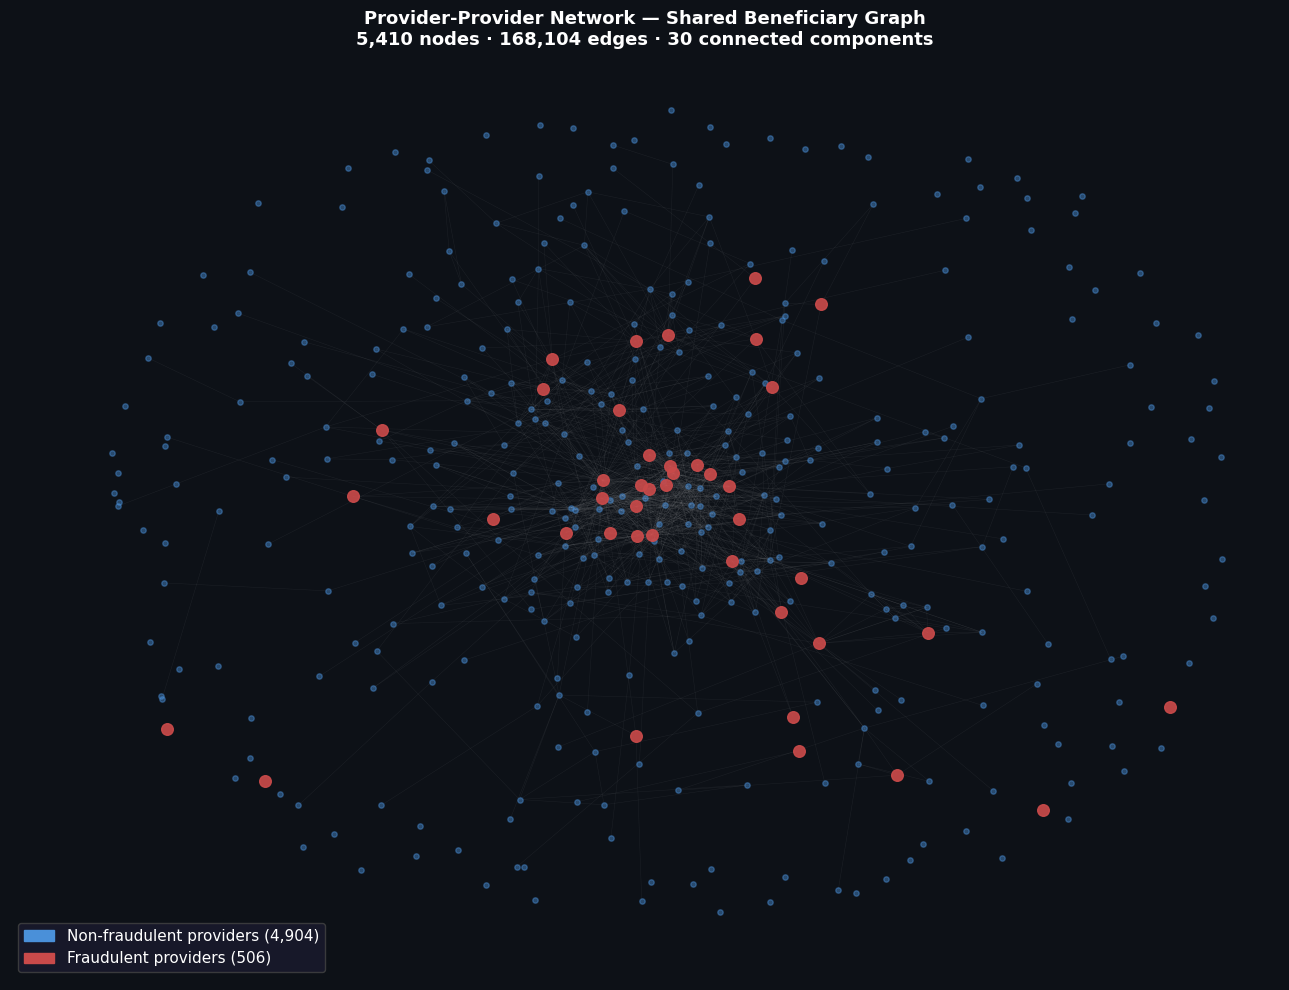

Network graph done


In [75]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Use your real graph G and real fraud labels
fraud_set = set(providers[providers['Label']==1]['Provider'])

# Sample 400 nodes for visibility
import random
random.seed(42)
sample = random.sample(list(G.nodes()), 400)
subgraph = G.subgraph(sample)
pos = nx.spring_layout(subgraph, seed=42, k=0.3)

clean = [n for n in sample if n not in fraud_set]
fraud = [n for n in sample if n in fraud_set]

fig, ax = plt.subplots(figsize=(13, 10), facecolor='#0d1117')
ax.set_facecolor('#0d1117')
nx.draw_networkx_edges(subgraph, pos, ax=ax, edge_color='white', alpha=0.06, width=0.4)
nx.draw_networkx_nodes(subgraph, pos, ax=ax, nodelist=clean, node_color='#4a90d9', node_size=15, alpha=0.45)
nx.draw_networkx_nodes(subgraph, pos, ax=ax, nodelist=fraud, node_color='#c94a4a', node_size=70, alpha=0.92)
ax.set_title('Provider-Provider Network — Shared Beneficiary Graph\n5,410 nodes · 168,104 edges · 30 connected components',
             color='white', fontsize=13, fontweight='bold', pad=15)
handles = [mpatches.Patch(color='#4a90d9', label='Non-fraudulent providers (4,904)'),
           mpatches.Patch(color='#c94a4a', label='Fraudulent providers (506)')]
ax.legend(handles=handles, loc='lower left', facecolor='#1a1a2e', edgecolor='#444', labelcolor='white', fontsize=11)
ax.axis('off')
plt.tight_layout()
plt.savefig(f'{OUT}/fig0_network_graph.png', dpi=200, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print("Network graph done")